# CDS 3301 — C2 Classification
## Pima Indians Diabetes Dataset

**Student:** Hillary Wekesa  
**Registration:** CT204/119566/24 | **Group:** 13

**Allocated task:** Predict diabetes `Outcome` using Logistic Regression and Random Forest.  
**Required settings:** stratified `test_size=0.25`, `random_state=9522`, five-fold stratified cross-validation.

This notebook is independent of the regression and clustering notebooks. It requires only the Pima Indians Diabetes CSV.

In [2]:


import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 9522
TEST_SIZE = 0.25
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Setup complete | random_state =", RANDOM_STATE, "| test_size =", TEST_SIZE)

Setup complete | random_state = 9522 | test_size = 0.25


## 1. Load the Pima Indians Diabetes dataset

Upload or place your Pima CSV (commonly named `diabetes.csv`) beside this notebook. It must contain the `Outcome` target column.

In [4]:
from pathlib import Path
matches = list(Path.cwd().glob("*.csv"))
matches += list(Path("/content").glob("*.csv")) if Path("/content").exists() else []
pima_path = next((str(p) for p in matches if "diabet" in p.name.lower() or "pima" in p.name.lower()), None)

if pima_path is None:
    try:
        from google.colab import files
        print("Upload the Pima Indians Diabetes CSV.")
        uploaded = files.upload()
        pima_path = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    except ImportError:
        pass

if pima_path is None:
    raise FileNotFoundError("Place diabetes.csv (or your Pima CSV) beside this notebook or upload it in Colab.")

df = pd.read_csv(pima_path)
df.columns = [str(c).strip() for c in df.columns]
target = next((c for c in ["Outcome", "outcome", "Class", "class"] if c in df.columns), None)
if target is None:
    raise ValueError(f"Could not find Outcome target. Columns: {list(df.columns)}")
if target != "Outcome":
    df = df.rename(columns={target: "Outcome"})
df["Outcome"] = pd.to_numeric(df["Outcome"], errors="coerce")
df = df.dropna(subset=["Outcome"]).copy()
df["Outcome"] = df["Outcome"].astype(int)

display(df.head())
print("Shape:", df.shape)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Shape: (768, 9)


## 2. Exploratory data analysis (EDA)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Missing values:


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Class counts:


,Count
Outcome,
0,500
1,268


Class proportions:


,Proportion
Outcome,
0,0.651042
1,0.348958


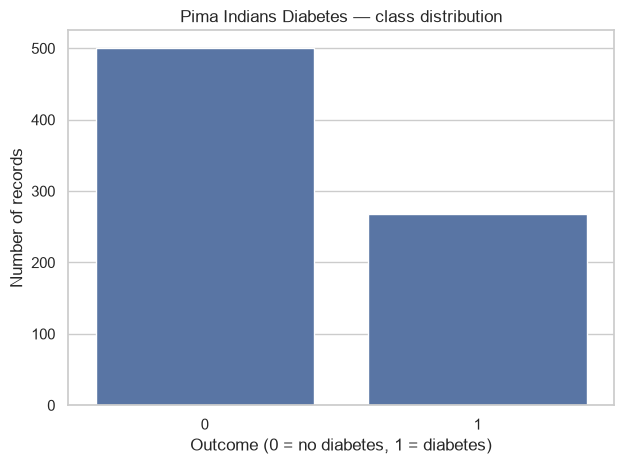

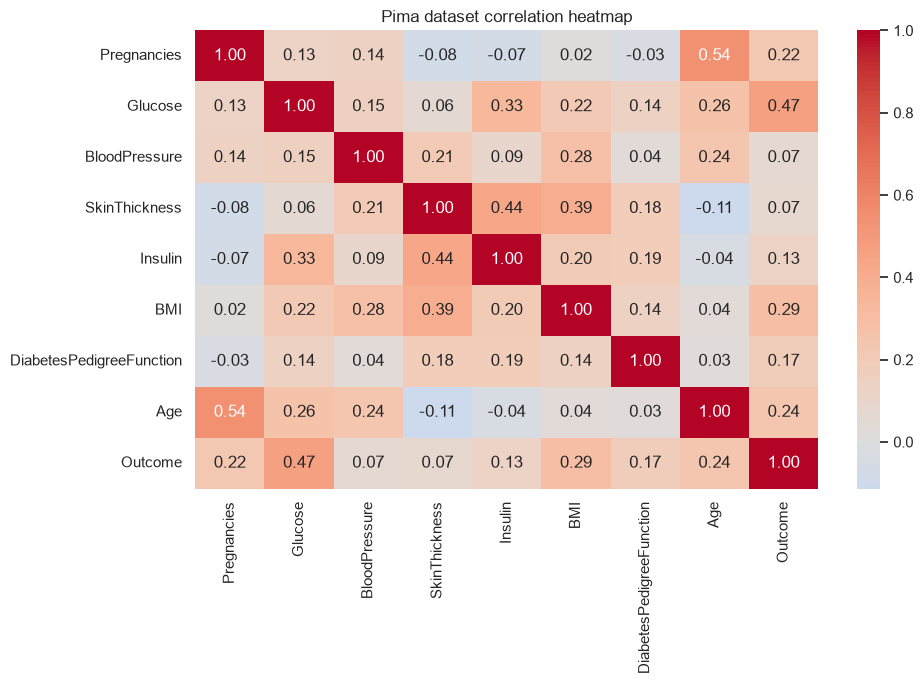

In [5]:
display(df.describe().T)
print("Missing values:")
display(df.isna().sum().to_frame("Missing values"))
print("Class counts:")
display(df["Outcome"].value_counts().sort_index().to_frame("Count"))
print("Class proportions:")
display(df["Outcome"].value_counts(normalize=True).sort_index().to_frame("Proportion"))

sns.countplot(data=df, x="Outcome")
plt.title("Pima Indians Diabetes — class distribution")
plt.xlabel("Outcome (0 = no diabetes, 1 = diabetes)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pima dataset correlation heatmap")
plt.tight_layout()
plt.show()

## 3. Preprocessing and stratified train/test split

In common Pima dataset versions, zero values in Glucose, BloodPressure, SkinThickness, Insulin and BMI may represent missing measurements. The code treats zeros as missing only in those columns when present. Verify this against the precise dataset version you downloaded.

In [6]:
X = df.drop(columns=["Outcome"]).copy()
y = df["Outcome"].copy()

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    print("Dropping non-numeric columns:", non_numeric)
    X = X.drop(columns=non_numeric)
X = X.apply(pd.to_numeric, errors="coerce")

for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
    if col in X.columns:
        X.loc[X[col] == 0, col] = np.nan

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Train proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("Proportion"))
print("Test proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("Proportion"))

Training rows: 576 | Test rows: 192
Train proportions:


,Proportion
Outcome,
0,0.651042
1,0.348958


Test proportions:


,Proportion
Outcome,
0,0.651042
1,0.348958


## 4. Train Logistic Regression and Random Forest

Report confusion matrices, accuracy, positive-class precision, recall, F1-score, ROC-AUC and five-fold stratified cross-validation scores.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    RocCurveDisplay
)

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

rows, fitted, predictions, probabilities = [], {}, {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    fitted[name], predictions[name], probabilities[name] = model, pred, prob

    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (positive class)": precision_score(y_test, pred, zero_division=0),
        "Recall (positive class)": recall_score(y_test, pred, zero_division=0),
        "F1-score (positive class)": f1_score(y_test, pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, prob),
        "CV accuracy": cv_scores["test_accuracy"].mean(),
        "CV precision": cv_scores["test_precision"].mean(),
        "CV recall": cv_scores["test_recall"].mean(),
        "CV F1": cv_scores["test_f1"].mean(),
        "CV ROC-AUC": cv_scores["test_roc_auc"].mean()
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

,Accuracy,Precision (positive class),Recall (positive class),F1-score (positive class),Test ROC-AUC,CV accuracy,CV precision,CV recall,CV F1,CV ROC-AUC
Model,,,,,,,,,,
Logistic Regression,0.7969,0.7593,0.6119,0.6777,0.8744,0.7570,0.7041,0.5377,0.6073,0.8185
Random Forest,0.8229,0.7391,0.7612,0.7500,0.8861,0.7326,0.6361,0.5473,0.5879,0.7978


## 5. Confusion matrices and ROC curves

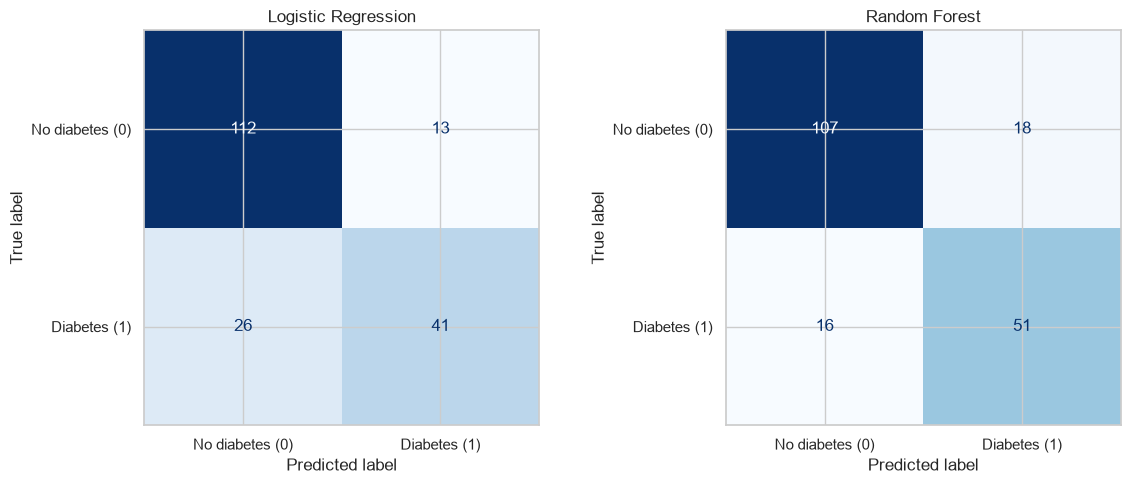

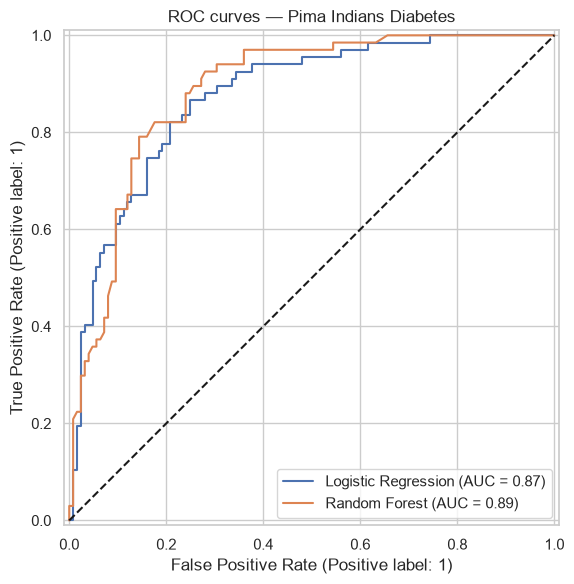

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes (0)", "Diabetes (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for name, prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("ROC curves — Pima Indians Diabetes")
plt.tight_layout()
plt.show()

## 6. Model recommendation and interpretation

In [9]:
for name in results.index:
    r = results.loc[name]
    print(
        f"{name}: recall={r['Recall (positive class)']:.3f}, "
        f"precision={r['Precision (positive class)']:.3f}, "
        f"F1={r['F1-score (positive class)']:.3f}, "
        f"ROC-AUC={r['Test ROC-AUC']:.3f}, "
        f"CV recall={r['CV recall']:.3f}"
    )

print("\nRecommendation guidance:")
print("For a screening-oriented discussion, consider positive-class recall because false negatives may delay follow-up.")
print("Also discuss precision and F1: an excessive number of false positives can create unnecessary follow-up.")
print("These models are educational predictions, not clinical diagnoses.")

Logistic Regression: recall=0.612, precision=0.759, F1=0.678, ROC-AUC=0.874, CV recall=0.538
Random Forest: recall=0.761, precision=0.739, F1=0.750, ROC-AUC=0.886, CV recall=0.547

Recommendation guidance:
For a screening-oriented discussion, consider positive-class recall because false negatives may delay follow-up.
Also discuss precision and F1: an excessive number of false positives can create unnecessary follow-up.
These models are educational predictions, not clinical diagnoses.
